# Task 56. Demonstration of Neural Networks

In [1]:
# ===== Implementing a Neural Network using NumPy =====
import numpy as np

# input data: 3 examples with 4 features each
X = np.array([[1, 0, 1, 0],
              [1, 0, 1, 1],
              [0, 1, 0, 1]])

# target output
y = np.array([[1], [1], [0]])

# sigmoid activation and its derivative
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# settings
epochs = 5000
lr = 0.1
n_inputs = X.shape[1]
n_hidden = 3
n_outputs = 1

# random weights and biases
w_hidden = np.random.uniform(size=(n_inputs, n_hidden))
b_hidden = np.random.uniform(size=(1, n_hidden))
w_out = np.random.uniform(size=(n_hidden, n_outputs))
b_out = np.random.uniform(size=(1, n_outputs))

for i in range(epochs):
    # forward propagation
    hidden = sigmoid(np.dot(X, w_hidden) + b_hidden)
    output = sigmoid(np.dot(hidden, w_out) + b_out)

    # backpropagation
    error = y - output
    d_output = error * sigmoid_derivative(output)
    error_hidden = d_output.dot(w_out.T)
    d_hidden = error_hidden * sigmoid_derivative(hidden)

    # update weights and biases
    w_out += hidden.T.dot(d_output) * lr
    b_out += np.sum(d_output, axis=0, keepdims=True) * lr
    w_hidden += X.T.dot(d_hidden) * lr
    b_hidden += np.sum(d_hidden, axis=0, keepdims=True) * lr

print(output)

[[0.96986055]
 [0.95856992]
 [0.05549625]]


## Understanding the implementation step by step

In [2]:
# ===== Importing libraries =====
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

In [3]:
print(np.__version__)
print(matplotlib.__version__)

2.4.6
3.11.2


In [4]:
# fix the random seed so the results can be reproduced
np.random.seed(42)

In [5]:
# ===== Creating the input and output data =====
X = np.array([[1, 0, 0, 0],
              [1, 0, 1, 1],
              [0, 1, 0, 1]])
print('Input:\n', X)
print('Shape of input:', X.shape)

Input:
 [[1 0 0 0]
 [1 0 1 1]
 [0 1 0 1]]
Shape of input: (3, 4)


In [6]:
# transpose so that each column is one example
X = X.T
print('Input in matrix form:\n', X)
print('Shape of input matrix:', X.shape)

Input in matrix form:
 [[1 1 0]
 [0 0 1]
 [0 1 0]
 [0 1 1]]
Shape of input matrix: (4, 3)


In [7]:
y = np.array([[1], [1], [0]])
y = y.T
print('Actual output:\n', y)
print('Shape of output:', y.shape)

Actual output:
 [[1 1 0]]
Shape of output: (1, 3)


In [8]:
# ===== Defining the architecture =====
inputLayer_neurons = X.shape[0]   # 4 features
hiddenLayer_neurons = 3
outputLayer_neurons = 1

In [9]:
# ===== Initializing the weights =====
weights_input_hidden = np.random.uniform(size=(inputLayer_neurons, hiddenLayer_neurons))
weights_hidden_output = np.random.uniform(size=(hiddenLayer_neurons, outputLayer_neurons))

In [10]:
print(weights_input_hidden.shape)
print(weights_hidden_output.shape)

(4, 3)


(3, 1)


In [11]:
# ===== Forward propagation =====
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [12]:
# linear transformation and activation of the hidden layer
hiddenLayer_linearTransform = np.dot(weights_input_hidden.T, X)
hiddenLayer_activations = sigmoid(hiddenLayer_linearTransform)
hiddenLayer_activations

array([[0.59255557, 0.75780746, 0.78696563],
       [0.72125881, 0.8626498 , 0.54403639],
       [0.67524268, 0.90912675, 0.75508227]])

In [13]:
# linear transformation and activation of the output layer
outputLayer_linearTransform = np.dot(weights_hidden_output.T, hiddenLayer_activations)
output = sigmoid(outputLayer_linearTransform)
output

array([[0.68334694, 0.72697078, 0.71257368]])

In [14]:
# ===== Calculating the error =====
error = np.square(y - output) / 2
error

array([[0.05013458, 0.03727248, 0.25388062]])

In [15]:
# ===== Backward propagation: gradient for weights_hidden_output =====
# chain rule: dE/dW = dE/dO * dO/dZ * dZ/dW
error_wrt_output = -(y - output)
output_wrt_outputLayer_LinearTransform = np.multiply(output, (1 - output))
outputLayer_LinearTransform_wrt_weights_hidden_output = hiddenLayer_activations

error_wrt_weights_hidden_output = np.dot(
    outputLayer_LinearTransform_wrt_weights_hidden_output,
    (error_wrt_output * output_wrt_outputLayer_LinearTransform).T)
error_wrt_weights_hidden_output.shape

(3, 1)

In [16]:
# ===== Backward propagation: gradient for weights_input_hidden =====
outputLayer_LinearTransform_wrt_hiddenLayer_activations = weights_hidden_output
hiddenLayer_activations_wrt_hiddenLayer_linearTransform = np.multiply(
    hiddenLayer_activations, (1 - hiddenLayer_activations))
hiddenLayer_linearTransform_wrt_weights_input_hidden = X

error_wrt_weights_input_hidden = np.dot(
    hiddenLayer_linearTransform_wrt_weights_input_hidden,
    (hiddenLayer_activations_wrt_hiddenLayer_linearTransform *
     np.dot(outputLayer_LinearTransform_wrt_hiddenLayer_activations,
            (output_wrt_outputLayer_LinearTransform * error_wrt_output))).T)
error_wrt_weights_input_hidden.shape

(4, 3)

In [17]:
# ===== Updating the weights =====
lr = 0.01

print('Weights before update:\n', weights_hidden_output, '\n', weights_input_hidden)

weights_hidden_output = weights_hidden_output - lr * error_wrt_weights_hidden_output
weights_input_hidden = weights_input_hidden - lr * error_wrt_weights_input_hidden

print('\nWeights after update:\n', weights_hidden_output, '\n', weights_input_hidden)

Weights before update:
 [[0.83244264]
 [0.21233911]
 [0.18182497]] 
 [[0.37454012 0.95071431 0.73199394]
 [0.59865848 0.15601864 0.15599452]
 [0.05808361 0.86617615 0.60111501]
 [0.70807258 0.02058449 0.96990985]]

Weights after update:
 [[0.83211079]
 [0.21250681]
 [0.18167831]] 
 [[0.37476062 0.95075719 0.7320294 ]
 [0.59845481 0.15594177 0.15594545]
 [0.05816641 0.86618978 0.60112315]
 [0.70795169 0.02052126 0.96986892]]


In [18]:
# ===== Training the model for many epochs =====
np.random.seed(42)
weights_input_hidden = np.random.uniform(size=(inputLayer_neurons, hiddenLayer_neurons))
weights_hidden_output = np.random.uniform(size=(hiddenLayer_neurons, outputLayer_neurons))

lr = 0.1
epochs = 1000
losses = []

for epoch in range(epochs):
    # forward propagation
    hiddenLayer_activations = sigmoid(np.dot(weights_input_hidden.T, X))
    output = sigmoid(np.dot(weights_hidden_output.T, hiddenLayer_activations))

    # error
    error = np.square(y - output) / 2

    # backward propagation
    error_wrt_output = -(y - output)
    output_wrt_Z2 = np.multiply(output, (1 - output))
    error_wrt_weights_hidden_output = np.dot(hiddenLayer_activations,
                                             (error_wrt_output * output_wrt_Z2).T)
    hidden_wrt_Z1 = np.multiply(hiddenLayer_activations, (1 - hiddenLayer_activations))
    error_wrt_weights_input_hidden = np.dot(
        X, (hidden_wrt_Z1 * np.dot(weights_hidden_output, output_wrt_Z2 * error_wrt_output)).T)

    # update weights
    weights_input_hidden = weights_input_hidden - lr * error_wrt_weights_input_hidden
    weights_hidden_output = weights_hidden_output - lr * error_wrt_weights_hidden_output

    losses.append(np.average(error))

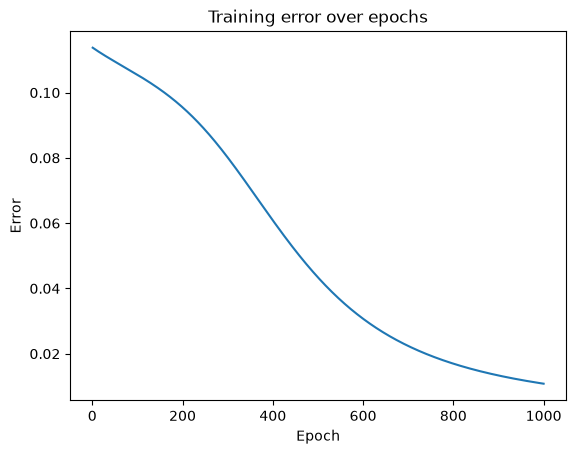

In [19]:
# ===== Visualizing the error =====
plt.plot(np.arange(1, epochs + 1), np.array(losses))
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title('Training error over epochs');

In [20]:
# final predictions vs. actual output
print('Predicted:', output)
print('Actual:   ', y)

Predicted: [[0.91428532 0.86697394 0.19958654]]
Actual:    [[1 1 0]]


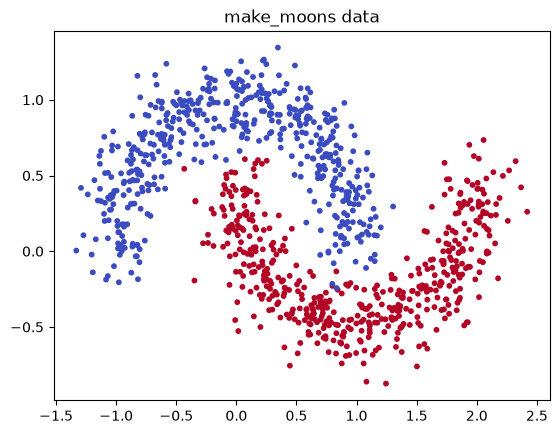

In [21]:
# ===== A bigger example: make_moons dataset =====
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=1000, noise=0.15, random_state=42)
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, s=10, cmap='coolwarm')
plt.title('make_moons data');

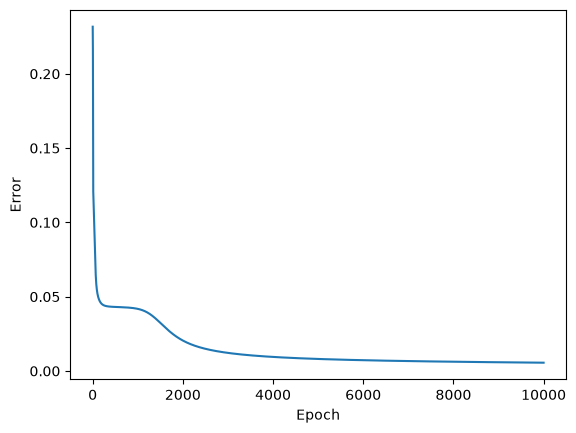

In [22]:
# a row of ones is added to the input so the hidden layer gets a bias term
X = np.vstack([X_moons.T, np.ones((1, X_moons.shape[0]))])
y = y_moons.reshape(1, -1)

inputLayer_neurons = X.shape[0]
hiddenLayer_neurons = 10
outputLayer_neurons = 1

np.random.seed(42)
weights_input_hidden = np.random.uniform(size=(inputLayer_neurons, hiddenLayer_neurons))
weights_hidden_output = np.random.uniform(size=(hiddenLayer_neurons, outputLayer_neurons))

lr = 2.0
epochs = 10000
losses = []

for epoch in range(epochs):
    hiddenLayer_activations = sigmoid(np.dot(weights_input_hidden.T, X))
    output = sigmoid(np.dot(weights_hidden_output.T, hiddenLayer_activations))
    error = np.square(y - output) / 2

    error_wrt_output = -(y - output)
    output_wrt_Z2 = np.multiply(output, (1 - output))
    error_wrt_weights_hidden_output = np.dot(hiddenLayer_activations,
                                             (error_wrt_output * output_wrt_Z2).T)
    hidden_wrt_Z1 = np.multiply(hiddenLayer_activations, (1 - hiddenLayer_activations))
    error_wrt_weights_input_hidden = np.dot(
        X, (hidden_wrt_Z1 * np.dot(weights_hidden_output, output_wrt_Z2 * error_wrt_output)).T)

    # gradients are summed over all 1000 examples, so divide by the number of examples
    weights_input_hidden -= lr * error_wrt_weights_input_hidden / X.shape[1]
    weights_hidden_output -= lr * error_wrt_weights_hidden_output / X.shape[1]

    losses.append(np.average(error))

plt.plot(np.arange(1, epochs + 1), np.array(losses))
plt.xlabel('Epoch')
plt.ylabel('Error');

Accuracy: 0.989


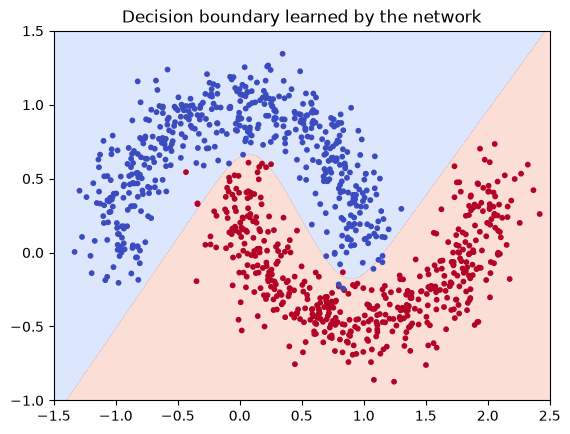

In [23]:
# accuracy and decision boundary
predictions = (output > 0.5).astype(int)
print('Accuracy:', (predictions == y).mean())

xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1, 1.5, 200))
grid = np.c_[xx.ravel(), yy.ravel(), np.ones(xx.size)].T
grid_out = sigmoid(np.dot(weights_hidden_output.T, sigmoid(np.dot(weights_input_hidden.T, grid))))
plt.contourf(xx, yy, grid_out.reshape(xx.shape), levels=[0, 0.5, 1], alpha=0.3, cmap='coolwarm')
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, s=10, cmap='coolwarm')
plt.title('Decision boundary learned by the network');